# Aula 14 — scikit-learn: Fluxo de Trabalho em ML (Teórica) · Conteúdo

**Unidade 4 — Aprendizado de Máquina Aplicado** · ver também: [exercícios](exercicios.ipynb) · [atividades](atividades.ipynb)

**🤖 Aula 14 — scikit-learn: Fluxo de Trabalho em ML (Teórica)**

Primeira aula da Unidade 4 (Aprendizado de Máquina Aplicado). API do scikit-learn (`fit`/`predict`/`transform`); divisão treino/teste; validação cruzada; pipelines de ML; métricas de classificação (acurácia, F1, ROC-AUC) e de regressão (RMSE, R²). Exemplo com **dados sintéticos de fácil entendimento** — quem vai cancelar o aplicativo de música fictício da Aula 12 (1.500 usuários) e, na regressão e no trabalho prático, os pedidos da hamburgueria fictícia (nenhum dado é real). Recursos: slides, Jupyter Notebook. Avaliação: **formulário avaliativo com 10 questões** e **trabalho prático (notebook de classificação)** — prazo de envio de ambos até 23/11/2026. Materiais desta aula: livro Tópicos de Estudo (5 capítulos) · apostila completa em PDF · slides · pacote com notebooks e datasets · formulário avaliativo · tarefa de entrega do trabalho prático.

---
## Tópicos de Estudo — Aula 14

### Descrição

Resumo dos principais tópicos da Aula 14 — scikit-learn: Fluxo de Trabalho em ML, em 5 capítulos curtos.

### 1. Aprendizado supervisionado, fluxo de trabalho e API

Nesta aula começamos a **Unidade 4 — Aprendizado de Máquina Aplicado**. O foco não é um algoritmo específico, mas o **fluxo de trabalho** que garante que um modelo seja avaliado de forma honesta.

#### O caso da aula (sintético)

1.500 usuários do aplicativo de música fictício da Aula 12, agora com a coluna `cancelou` (1 = cancelou a conta no mês seguinte; 27% dos usuários). Pergunta: *quem tem risco de cancelar?* No trabalho prático, os 600 pedidos da hamburgueria da Aula 12: *quem vai ficar insatisfeito?*

#### Classificação × regressão

|  |  |  |
|----|----|----|
|  | Classificação | Regressão |
| Alvo | categoria (cancelou / ficou) | número (minutos de entrega) |
| Modelos | LogisticRegression, DecisionTreeClassifier, RandomForestClassifier | LinearRegression, RandomForestRegressor |
| Métricas | acurácia, precisão, recall, F1, ROC-AUC | MAE, RMSE, R² |

#### O fluxo em oito etapas

1.  Pergunta e alvo
2.  X (atributos) e y (alvo)
3.  Treino / teste
4.  Baseline
5.  Pipeline (pré-processamento + modelo)
6.  Validação cruzada
7.  Teste final e métricas
8.  Limiar e decisão

#### A API do scikit-learn

- **Estimador** (modelo): `fit(X, y)` aprende; `predict(X)` prevê; `predict_proba(X)` dá a probabilidade de cada classe.
- **Transformador**: `fit(X)` aprende parâmetros; `transform(X)` aplica; `fit_transform(X)` faz os dois.
- O que foi aprendido fica em atributos terminados em `_` (`coef_`, `mean_`).

In [ ]:
modelo = LogisticRegression(max_iter=1000)
modelo.fit(X_treino, y_treino)
modelo.predict_proba(X_teste)[:, 1]   # probabilidade de cancelar

### 2. Treino/teste, vazamento e baseline

#### Treino e teste

Avaliar o modelo nos dados em que ele aprendeu dá um resultado otimista. Separamos uma parte para **teste** e só a usamos no fim.

In [ ]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

- `stratify=y`: mesma proporção de classes nos dois conjuntos (26,8% e 26,9% de cancelamentos).
- `random_state`: sorteio fixo, resultados reproduzíveis.

#### Vazamento de dados (data leakage)

O modelo não pode receber, no treino, informação que não teria no uso real. Dois casos frequentes:

1.  **Pré-processar antes de dividir**: padronizar ou imputar com a média de todos os dados faz o treino "ver" o teste. Solução: `Pipeline`.
2.  **Atributo que carrega a resposta** ou só existe depois dela: usar a avaliação para prever a insatisfação; usar o tempo de entrega para prever a insatisfação "no momento do pedido".

#### Baseline e o paradoxo da acurácia

O `DummyClassifier(strategy="most_frequent")` sempre prevê a classe mais comum. No caso da aula, ele tem **73,1% de acurácia** e **recall 0**: não encontra nenhum cliente que vai cancelar. Em dados desbalanceados, acurácia alta pode esconder um modelo inútil. Todo modelo deve ser comparado com o baseline.

### 3. Pré-processamento e pipelines

#### Pré-processamento

|  |  |
|----|----|
| Problema | Transformador |
| valores faltantes (satisfação em branco) | `SimpleImputer(strategy="median")` |
| escalas diferentes (dias, horas, anúncios) | `StandardScaler()` |
| categorias (plano, dispositivo) | `OneHotEncoder(handle_unknown="ignore")` |

#### ColumnTransformer + Pipeline

O `ColumnTransformer` aplica cada tratamento às suas colunas. O `Pipeline` encadeia o pré-processamento e o modelo em **um único estimador**.

In [ ]:
preprocess = ColumnTransformer([
    ("num", Pipeline([("imputar", SimpleImputer(strategy="median")),
                      ("padronizar", StandardScaler())]), numericas),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)])
modelo = Pipeline([("preprocess", preprocess),
                   ("classificador", LogisticRegression(max_iter=1000))])
modelo.fit(X_treino, y_treino)   # tudo aprende só com o treino

**Vantagens:** sem vazamento (inclusive na validação cruzada), um só `fit` e um só `predict`, troca de modelo em uma linha e um único objeto para salvar.

#### O que o modelo aprendeu

Pelos coeficientes da regressão logística (variáveis padronizadas): **plano gratuito, dias sem acessar e chamados ao suporte aumentam** o risco de cancelar; **satisfação, meses de conta e plano Premium diminuem**. São associações, não causas.

### 4. Métricas de classificação e limiar de decisão

#### Matriz de confusão (teste, 375 usuários)

|                    |                                |                        |
|--------------------|--------------------------------|------------------------|
|                    | previsto: ficou                | previsto: cancelou     |
| **real: ficou**    | VN = 255                       | FP = 19 (falso alarme) |
| **real: cancelou** | FN = 46 (cancelamento perdido) | VP = 55                |

#### Métricas

|  |  |  |  |
|----|----|----|----|
| Métrica | Fórmula | Pergunta | Valor |
| Acurácia | (VP + VN) / total | quantos acertos no geral? | 0,827 |
| Precisão | VP / (VP + FP) | dos apontados, quantos cancelaram? | 0,743 |
| Recall | VP / (VP + FN) | dos que cancelaram, quantos foram encontrados? | 0,545 |
| F1 | 2·P·R / (P + R) | equilíbrio entre precisão e recall | 0,629 |
| ROC-AUC | área sob a curva ROC | o modelo ordena bem o risco? | 0,831 |

#### ROC-AUC

A curva ROC mostra recall × taxa de falsos positivos em todos os limiares; a AUC resume: 0,5 = chute, 1,0 = perfeito. AUC = 0,83: sorteando um cliente que cancelou e um que ficou, o modelo dá risco maior ao primeiro em 83% das vezes.

#### Limiar de decisão

O `predict` usa 0,5. Baixar o limiar aumenta o recall e reduz a precisão: com 0,3, o modelo encontra 70% dos cancelamentos (contra 55%), apontando 134 clientes em vez de 74. **O limiar é uma decisão de negócio**, que depende do custo de cada tipo de erro.

In [ ]:
proba = modelo.predict_proba(X_teste)[:, 1]
pred_03 = (proba >= 0.3).astype(int)

### 5. Validação cruzada, regressão e avaliação

#### Validação cruzada

Uma única divisão depende da sorte. Na validação cruzada **k-fold**, o treino é dividido em k partes; o modelo é treinado k vezes, cada vez validado em uma parte diferente. Resultado: **média ± desvio-padrão**. Serve para **escolher** o modelo; o teste fica guardado.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
r = cross_validate(modelo, X_treino, y_treino, cv=cv,
                   scoring=["accuracy", "f1", "roc_auc"])

|                     |          |       |               |
|---------------------|----------|-------|---------------|
| Modelo              | Acurácia | F1    | ROC-AUC       |
| Baseline            | 0,732    | 0,000 | 0,500         |
| Regressão logística | 0,803    | 0,564 | 0,845 ± 0,029 |
| Árvore de decisão   | 0,787    | 0,527 | 0,778 ± 0,032 |
| Random forest       | 0,806    | 0,556 | 0,838 ± 0,026 |

#### Métricas de regressão (tempo de entrega)

- **MAE** = 3,94 min — erro típico, na unidade do alvo.
- **RMSE** = 6,84 min — pune mais os erros grandes (baseline: 10,75 min).
- **R²** = 0,59 — proporção da variação explicada (0 = prever sempre a média).

#### Materiais e avaliação

- **Apostila (PDF)** e **slides** da aula.
- **Pacote**: notebook guiado com saídas, notebook do trabalho prático, dados e `gerar_dados.py`.
- **Trabalho prático** (entrega): classificação dos clientes insatisfeitos da hamburgueria — prazo **23/11/2026, 23:59**.
- **Formulário avaliativo**: 10 questões objetivas — prazo **23/11/2026, 23:59**.

---
## Conteúdo — Aula 14 (PDF)

> Apostila completa da Aula 14 — scikit-learn: Fluxo de Trabalho em ML: classificação × regressão, o fluxo de trabalho em oito etapas, a API do scikit-learn, treino/teste e vazamento de dados, baseline e paradoxo da acurácia, pré-processamento e pipelines, métricas de classificação, ROC-AUC e limiar, validação cruzada e métricas de regressão, com o roteiro do exemplo guiado, o enunciado do trabalho prático e uma colinha de comandos.

> Convertido de [`Aula14_scikit_learn_Fluxo_ML.pdf`](Aula14_scikit_learn_Fluxo_ML.pdf) (o original está nesta pasta — confira nele figuras e diagramação).

INSTITUTO FEDERAL DE EDUCAÇÃO, CIÊNCIA E TECNOLOGIA DO RIO GRANDE DO NORTE ESPECIALIZAÇÃO EM CIÊNCIA DE DADOS · DISCIPLINA: ANÁLISE E CIÊNCIA DE DADOS

### Aula 14 - scikit-learn: Fluxo de Trabalho em ML

API do scikit-learn (fit/predict/transform); treino/teste; validação cruzada; pipelines de ML; métricas de classificação (acurácia, F1, ROC-AUC) e de regressão (RMSE, R²)

| Unidade | Unidade 4 - Aprendizado de Máquina Aplicado (Aula 14, primeira aula da unidade) |
|----------------|------------------------------------------------------------------------------------------------------------------------|
| Natureza | Aula teórica, com exemplo guiado em Jupyter Notebook |
| Duração | 1h30 - exposição com slides intercalada ao exemplo guiado |
| Pré-requisitos | Pandas (Aulas 04-05), preparação de dados (Aulas 09-10), AED e correlação (Aulas 11-12) |
| Recursos | Slides, Jupyter Notebook, scikit-learn , pandas , matplotlib / seaborn ; dados sintéticos |
| Avaliação | Formulário avaliativo (10 questões) + trabalho prático (notebook de classificação) - prazo de ambos: 23/11/2026, 23:59 |
| Professor | Plácido Antônio de Souza Neto |

### Objetivos de aprendizagem

Ao final desta aula, espera-se que o estudante seja capaz de:

- Distinguir problemas de classificação e de regressão e identificar atributos (X) e alvo (y). 1.
- Usar a API padrão do scikit-learn: estimadores ( fit , predict , predict\_proba ) e transformadores ( fit , transform ). 2.
- Separar treino e teste corretamente, com estratificação, e evitar vazamento de dados. 3.
- Montar um Pipeline com ColumnTransformer (imputação, padronização, one-hot) e um modelo. 4.
- Avaliar classificadores com matriz de confusão, acurácia, precisão, recall, F1 e ROCAUC, e regressores com MAE, RMSE e R². 5.
- Comparar modelos com validação cruzada e escolher o limiar de decisão de acordo com o problema. 6.

### Sumário

### Parte I - Fundamentos

- 1.1 Aprendizado supervisionado · 1.2 O fluxo de trabalho · 1.3 A API do scikit-learn · 1.4 Treino, teste e vazamento
- 1.5 Baseline e o paradoxo da acurácia · 1.6 Pré-processamento · 1.7 Pipelines · 1.8 Métricas de classificação
- 1.9 ROC-AUC e limiar de decisão · 1.10 Validação cruzada · 1.11 Métricas de regressão · 1.12 Erros comuns

Parte II - Exemplo guiado: quem vai cancelar o app de música?

Parte III - Trabalho prático (entrega): clientes insatisfeitos da hamburgueria

Parte IV - Formulário avaliativo

Apêndice A - Colinha do scikit-learn · Apêndice B - Referências

### SOBRE OS DADOS USADOS NESTA AULA

Os dados são sintéticos . O exemplo guiado usa 1.500 usuários do aplicativo de música fictício da Aula 12, agora com a coluna cancelou (1 = cancelou a conta no mês seguinte; 27% dos usuários) e cerca de 4% de respostas de satisfação em branco. O trabalho prático e o exemplo de regressão usam os 600 pedidos da hamburgueria fictícia Brasa &amp; Pão (Aula 12). Nenhum registro corresponde a pessoa ou empresa real.

### Parte I - Fundamentos

Do dado ao modelo avaliado: um fluxo que vale para qualquer problema supervisionado

### 1.1 Aprendizado supervisionado: classificação × regressão

No aprendizado supervisionado , o modelo aprende a partir de exemplos em que a resposta já é conhecida: um conjunto de atributos (X) e um alvo (y). Depois, prevê o alvo para casos novos.

| | Classificação | Regressão |
|---------------------|---------------------------------------------------------------------------|------------------------------------------------------------------|
| Alvo | categoria (ex.: cancelou / ficou) | número (ex.: minutos de entrega) |
| Saída do modelo | classe prevista e probabilidade de cada classe | valor previsto |
| Exemplos de modelos | LogisticRegression , DecisionTreeClassifier , RandomForestClassifier | LinearRegression , DecisionTreeRegressor , RandomForestRegressor |
| Métricas | acurácia, precisão, recall, F1, ROC-AUC | MAE, RMSE, R² |
| Nesta aula | quem vai cancelar o app (exemplo guiado); cliente insatisfeito (trabalho) | tempo de entrega da hamburgueria |

### 1.2 O fluxo de trabalho

Figura 1 - As oito etapas que seguiremos. As etapas 5 e 6 são o coração do scikit-learn.

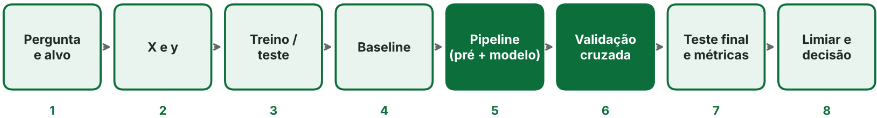

Esse fluxo é o que separa um modelo confiável de um número bonito: a ordem das etapas evita que informação do teste "vaze" para o treino e garante que o desempenho reportado seja o que o modelo terá com dados novos.

### 1.3 A API do scikit-learn

Todos os objetos seguem o mesmo contrato - aprender um modelo novo é trocar uma linha de código.

| Tipo | Métodos | Exemplos |
|--------------------|------------------------------------------------------------------------------------------------------|----------------------------------------------------------------|
| Estimador (modelo) | fit(X, y) aprende; predict(X) prevê; predict_proba(X) dá a probabilidade de cada classe; score(X, y) | LogisticRegression , RandomForestClassifier , LinearRegression |
| Transformador | fit(X) aprende parâmetros; transform(X) aplica; fit_transform(X) | StandardScaler , OneHotEncoder , SimpleImputer |
| Pipeline | encadeia transformadores + estimador e se comporta como um estimador | Pipeline , ColumnTransformer |

In [ ]:
from sklearn.linear_model import LogisticRegression
modelo = LogisticRegression(max_iter=1000)   # 1. escolher e configurar (hiperparâmetros)
modelo.fit(X_treino, y_treino)               # 2. aprender com o treino
modelo.predict(X_teste)                      # 3. prever classes
modelo.predict_proba(X_teste)[:, 1]          #    ... ou a probabilidade da classe 1
modelo.coef_                                 # o que foi aprendido termina com "_"

### 1.4 Treino, teste e vazamento de dados

Avaliar o modelo nos mesmos dados em que ele aprendeu é como corrigir a prova com o gabarito na mão: o resultado é otimista. Separamos uma parte (geralmente 20-30%) como teste , que só é usada no fim.

In [ ]:
from sklearn.model_selection import train_test_split
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)   # 1.125 treino | 375 teste

- stratify=y mantém a mesma proporção de classes nos dois conjuntos (26,8% e 26,9% de cancelamentos) - essencial com classes desbalanceadas. ·
- random\_state fixa o sorteio: resultados reproduzíveis. ·

### VAZAMENTO DE DADOS (DATA LEAKAGE)

Acontece quando o modelo recebe, no treino, informação que não teria no uso real. Dois tipos frequentes: (1) ajustar o pré-processamento em todos os dados antes de dividir (a média da padronização "vê" o teste); (2) usar como atributo uma variável que contém a resposta ou que só existe depois dela (ex.: usar a avaliação para prever a insatisfação, ou o tempo de entrega para prever a insatisfação "no momento do pedido"). O pipeline resolve o primeiro tipo; o segundo exige pensar no problema.

### 1.5 Baseline e o paradoxo da acurácia

O baseline é o desempenho de uma regra trivial. O DummyClassifier(strategy="most\_frequent") sempre prevê a classe mais comum. No exemplo guiado, ele acerta 73,1% - sem encontrar nenhum cliente que vai cancelar (recall = 0). Esse é o paradoxo da acurácia : em dados desbalanceados, uma acurácia alta pode esconder um modelo inútil. Todo modelo deve ser comparado com o baseline, e a métrica deve refletir o objetivo (aqui, encontrar quem vai cancelar).

### 1.6 Pré-processamento

| Problema | Transformador | O que aprende no fit |
|----------------------------------------------|----------------------------------------|----------------------------------------|
| Valores faltantes | SimpleImputer(strategy="median") | a mediana de cada coluna (no treino) |
| Escalas diferentes (dias × horas × anúncios) | StandardScaler() | média e desvio-padrão → z-score |
| Texto/categorias (plano, dispositivo) | OneHotEncoder(handle_unknown="ignore") | as categorias existentes → colunas 0/1 |

O ColumnTransformer aplica cada tratamento às suas colunas e junta o resultado em uma única matriz.

### 1.7 Pipelines

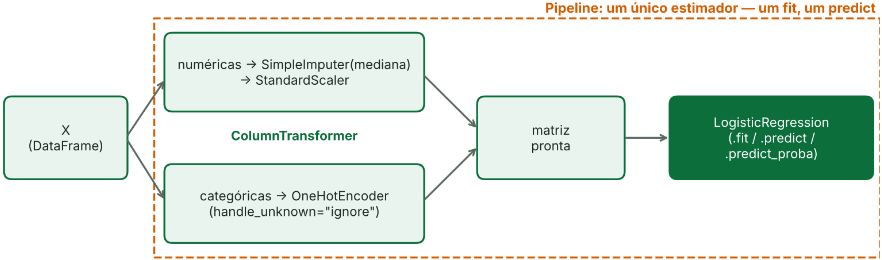

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
preprocess = ColumnTransformer([
    ("num", Pipeline([("imputar", SimpleImputer(strategy="median")),
                      ("padronizar", StandardScaler())]), numericas),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)])
modelo = Pipeline([("preprocess", preprocess),
                   ("classificador", LogisticRegression(max_iter=1000))])
modelo.fit(X_treino, y_treino)        # tudo aprende SÓ com o treino
modelo.predict(X_teste)               # tudo é APLICADO no teste

Figura 2 - Um Pipeline encadeia o pré-processamento (ColumnTransformer) e o modelo em um único estimador.

Vantagens: sem vazamento (inclusive dentro da validação cruzada), código curto, fácil trocar o modelo ( ("classificador", RandomForestClassifier()) ) e um único objeto para salvar e colocar em produção.

Figura 3 - Coeficientes da regressão logística (variáveis padronizadas): plano gratuito, dias sem acessar e chamados ao suporte aumentam o risco; satisfação, tempo de conta e plano Premium diminuem.

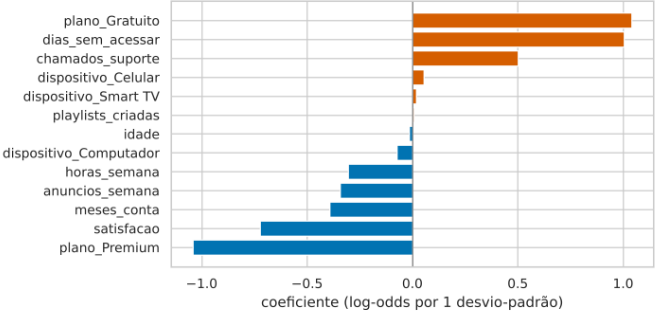

### 1.8 Métricas de classificação

Tudo começa na matriz de confusão , que cruza o real com o previsto:

| | previsto: ficou (0) | previsto: cancelou (1) |
|--------------------|---------------------------|--------------------------|
| real: ficou (0) | VN - verdadeiro negativo | FP - falso alarme |
| real: cancelou (1) | FN - cancelamento perdido | VP - verdadeiro positivo |

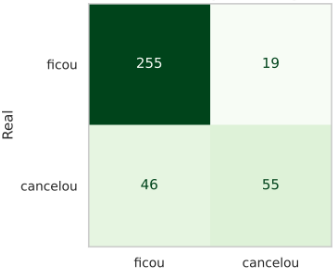

Figura 4 - Regressão logística no teste (375 usuários): VN = 255, FP = 19, FN = 46, VP = 55.

| Métrica | Fórmula | Pergunta | Baseline | Reg. logística |
|-------------------------------|--------------------------------------------------------|------------------------------------|-------------|------------------|
| (VP + VN) / total | quantos acertos no geral? | 0,731 | 0,827 | Acurácia |
| VP / (VP + FP) | dos apontados como "vai cancelar", quantos cancelaram? | - | 0,743 | Precisão |
| VP / (VP + FN) | dos que cancelaram, quantos | foram encontrados? | 0,000 0,545 | Recall |
| F1 | 2·P·R / (P + R) | equilíbrio entre precisão e recall | 0,000 | 0,629 |
| ROC- AUC área sob a curva ROC | | o modelo ordena bem o risco? | 0,500 | 0,831 |

Conferindo à mão: precisão = 55 / (55 + 19) = 0,743; recall = 55 / (55 + 46) = 0,545; F1 = 2 × 0,743 × 0,545 / (0,743 + 0,545) = 0,629.

### 1.9 ROC-AUC e o limiar de decisão

O predict transforma a probabilidade em classe usando o limiar 0,5. A curva ROC mostra o desempenho em todos os limiares (taxa de verdadeiros positivos × taxa de falsos positivos), e a AUC resume em um número: 0,5 = chute, 1,0 = separação perfeita. Interpretação: AUC = 0,83 significa que, sorteando um cliente que cancelou e um que ficou, o modelo dá risco maior ao primeiro em 83% das vezes. A ROC-AUC não depende do limiar e é pouco afetada pelo desbalanceamento - por isso é muito usada para comparar modelos.

Figura 5 - Curva ROC no teste.

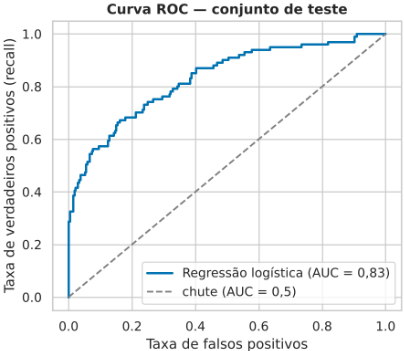

| Limiar | 0,2 | 0,3 | 0,4 | 0,5 (padrão) | 0,6 | 0,7 |
|--------------------|-------|-------|-------|----------------|-------|-------|
| Precisão | 0,460 | 0,530 | 0,639 | 0,743 | 0,875 | 0,943 |
| Recall | 0,802 | 0,703 | 0,614 | 0,545 | 0,416 | 0,327 |
| Clientes apontados | 176 | 134 | 97 | 74 | 48 | 35 |

Se perder um cliente custa muito mais do que dar um desconto desnecessário, um limiar de 0,3 encontra 70% dos cancelamentos (contra 55%) - ao custo de mais falsos alarmes. O limiar é uma decisão de negócio , não do algoritmo.

### 1.10 Validação cruzada

Uma única divisão treino/teste depende da sorte do sorteio. Na validação cruzada k-fold , o treino é dividido em k partes; o modelo é treinado k vezes, cada vez validado em uma parte diferente, e o resultado é a média ± desvio-padrão . Ela serve para comparar e escolher modelos sem tocar no teste.

Figura 6 - Precisão, recall e F1 conforme o limiar.

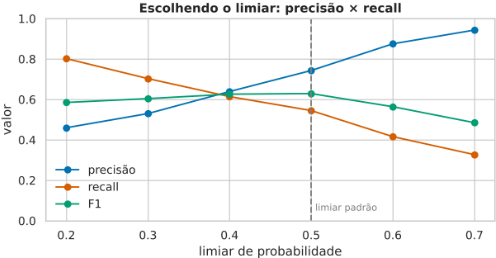

Figura 7 - Validação cruzada com k = 5. StratifiedKFold mantém a proporção de classes em cada parte.

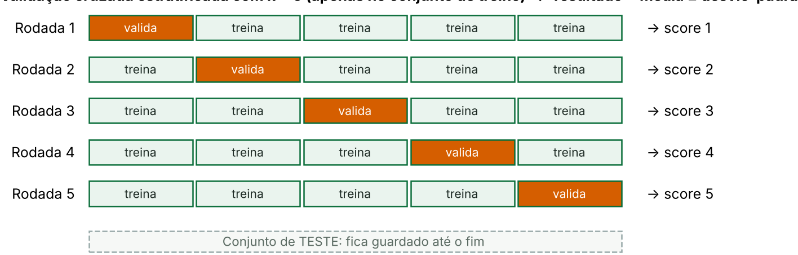

from sklearn.model\_selection import StratifiedKFold, cross\_validate cv = StratifiedKFold(n\_splits=5, shuffle=True, random\_state=42) r = cross\_validate(modelo, X\_treino, y\_treino, cv=cv, scoring=["accuracy", "f1", "roc\_auc"]) r["test\_roc\_auc"].mean(), r["test\_roc\_auc"].std()

| Modelo (no mesmo pipeline) | Acurácia | F1 | ROC-AUC (média ± dp) |
|------------------------------------|------------|-------|------------------------|
| Baseline (Dummy) | 0,732 | 0,000 | 0,500 ± 0,000 |
| Regressão logística | 0,803 | 0,564 | 0,845 ± 0,029 |
| Árvore de decisão (profundidade 4) | 0,787 | 0,527 | 0,778 ± 0,032 |
| Random forest (300 árvores) | 0,806 | 0,556 | 0,838 ± 0,026 |

Figura 8 - ROC-AUC em cada um dos 5 folds. A regressão logística e a random forest empatam na prática; a árvore rasa fica atrás.

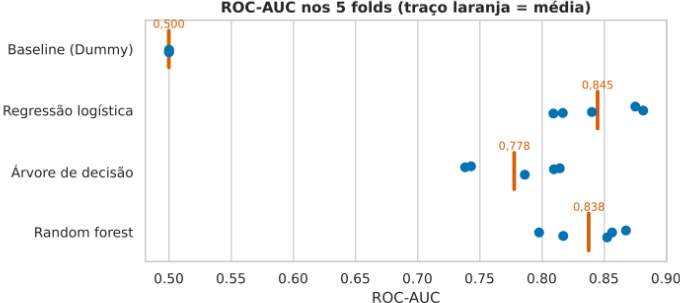

### 1.11 Métricas de regressão

| Métrica | Fórmula | Leitura | Exemplo (tempo de entrega) |
|-----------|----------------------------|-------------------------------------------------------------|------------------------------|
| MAE | média de &#124;y - ŷ&#124; | erro típico, na unidade do alvo | 3,94 min |
| RMSE | √ média de (y - ŷ)² | pune mais os erros grandes; sempre ≥ MAE | 6,84 min (baseline: 10,75) |
| R² | 1 - SQ res / SQ tot | proporção da variação explicada; 0 = igual a prever a média | 0,59 |

Figura 9 - Real × previsto. Os pontos isolados à direita são atrasos excepcionais.

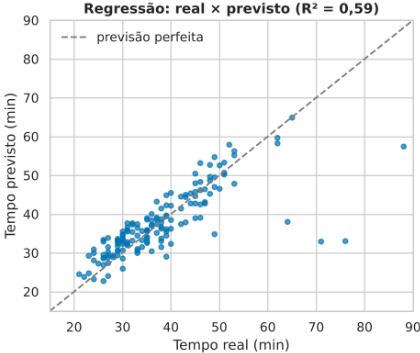

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error,
    root_mean_squared_error, r2_score)
reg = Pipeline([("preprocess", preproc),
                ("regressor", LinearRegression())])
reg.fit(X_treino, y_treino)
pred = reg.predict(X_teste)
mean_absolute_error(y_teste, pred)       # 3,94
root_mean_squared_error(y_teste, pred)   # 6,84
r2_score(y_teste, pred)                  # 0,59
# validação cruzada: scoring="neg_root_mean_squared_error"
# (o sinal é negativo porque o sklearn sempre maximiza)

A distância entre RMSE (6,84) e MAE (3,94) indica que poucos erros grandes pesam muito - os atrasos excepcionais que nenhuma variável explica.

### 1.12 Erros comuns

- Avaliar no próprio treino, ou usar o teste várias vezes para "ajustar" o modelo. 1.
- Padronizar ou imputar antes de dividir os dados (vazamento) - use pipeline. 2.
- Reportar só a acurácia em dados desbalanceados; não comparar com o baseline. 3.
- Esquecer stratify=y e random\_state . 4.
- Usar como atributo uma variável que carrega a resposta ou só existe depois dela. 5.
- Reportar a validação cruzada sem o desvio-padrão. 6.

### Parte II - Exemplo guiado: quem vai cancelar o app de música?

### Notebook Aula14\_Fluxo\_ML\_scikit\_learn.ipynb · 1h30

| Tempo | Parte do notebook | O que fazer | Resultado de referência |
|-----------|----------------------------|----------------------------------------------------------------------|--------------------------------------------------------|
| 0-10 min | 0. Dados e pergunta | carregar, ver proporção das classes, faltantes e boxplots por classe | 1.500 × 12; 26,9% cancelaram; 60 satisfações em branco |
| 10-20 min | 1. API do scikit- learn | StandardScaler : fit , mean_ , transform | médias 13,76 h e 6,65 dias |
| 20-30 min | 2. Treino/teste e baseline | divisão estratificada; DummyClassifier | 1.125/375; baseline 73,1% e recall 0 |
| 30-45 min | 3. Pipeline | ColumnTransformer + LogisticRegression ; coeficientes | pipeline treinado; Figura 3 |
| 45-60 min | 4. Métricas | matriz de confusão, relatório, ROC, limiar | acurácia 0,827; F1 0,629; AUC 0,831 |
| 60-75 min | 5. Validação cruzada | 5 folds estratificados; 4 modelos | logística 0,845 ± 0,029 de AUC |
| 75-85 min | 6. Regressão | tempo de entrega com LinearRegression | MAE 3,94; RMSE 6,84; R² 0,59 |
| 85-90 min | Fechamento | checklist do fluxo; apresentar o trabalho prático | - |

### Parte III - Trabalho prático (entrega no Moodle)

Notebook Aula14\_Trabalho\_Pratico.ipynb · prazo 23/11/2026, 23:59

Pergunta: com os dados do pedido e da entrega da hamburgueria (Aula 12), o modelo consegue identificar os clientes insatisfeitos (avaliação ≤ 3)? O notebook traz o enunciado de cada etapa e células marcadas com TODO .

| Etapa | O que fazer | Para conferir | Pontos |
|---------|-----------------------------------------------------------------------------------------------------------------------------------------------|---------------------------|----------|
| 1 | Criar o alvo insatisfeito e ver a proporção das classes | 167 insatisfeitos (27,8%) | 10 |
| 2 | Definir X (5 numéricas + 5 categóricas, sem avaliacao ) e y; treino/ teste estratificado (25%, random_state=42 ) | 450 / 150 pedidos | 15 |
| 3 | Baseline com DummyClassifier | acurácia ≈ 0,72; F1 = 0 | 10 |
| 4 | Pipeline ( StandardScaler + OneHotEncoder ) + regressão logística; acurácia, F1, ROC-AUC, matriz de confusão e classification_report no teste | ROC-AUC entre 0,75 e 0,85 | 25 |
| 5 | Segundo modelo (árvore ou random forest) no mesmo pipeline | - | 10 |
| 6 | Validação cruzada estratificada (5 folds) comparando baseline e os dois modelos: média ± dp de acurácia, F1 e ROC-AUC | tabela com 3 modelos | 20 |
| 7 | Conclusão (5-8 linhas): modelo escolhido e métrica; leitura dos erros; o que muda para prever no momento do pedido | - | 10 |

O que entregar: o arquivo .ipynb executado (com as saídas visíveis), na tarefa Trabalho Prático - Aula 14 do Moodle. Prazo: 23/11/2026, 23:59.


> **Parte avaliativa desta apostila → [atividades.ipynb](atividades.ipynb).**

### Apêndice A - Colinha do scikit-learn

```
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score from sklearn.compose import ColumnTransformer from sklearn.pipeline import Pipeline from sklearn.impute import SimpleImputer from sklearn.preprocessing import StandardScaler, OneHotEncoder from sklearn.dummy import DummyClassifier, DummyRegressor from sklearn.linear_model import LogisticRegression, LinearRegression from sklearn.tree import DecisionTreeClassifier from sklearn.ensemble import RandomForestClassifier from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, classification_report, mean_absolute_error, root_mean_squared_error, r2_score) X, y = df.drop(columns=["alvo"]), df["alvo"] X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42) pre = ColumnTransformer([ ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), numericas), ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)]) modelo = Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=1000))]).fit(X_tr, y_tr) pred, proba = modelo.predict(X_te), modelo.predict_proba(X_te)[:, 1] accuracy_score(y_te, pred); f1_score(y_te, pred); roc_auc_score(y_te, proba) ConfusionMatrixDisplay.from_predictions(y_te, pred); print(classification_report(y_te, pred)) pred_03 = (proba >= 0.3).astype(int)                       # outro limiar cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) r = cross_validate(modelo, X_tr, y_tr, cv=cv, scoring=["accuracy", "f1", "roc_auc"]) r["test_roc_auc"].mean(), r["test_roc_auc"].std() modelo.set_params(clf=RandomForestClassifier(random_state=42))   # trocar o modelo modelo.named_steps["pre"].get_feature_names_out()                  # nomes após o préprocessamento # regressão -cross_val_score(reg, X_tr, y_tr, cv=5, scoring="neg_root_mean_squared_error")
```

### Checklist do fluxo de ML

- Pergunta e alvo definidos; proporção das classes verificada. 1.
- Atributos sem vazamento (nada que contenha a resposta ou venha depois dela). 2.
- Treino/teste separados (estratificado) e teste guardado. 3.
- Baseline calculado. 4.
- Todo o pré-processamento dentro de um Pipeline . 5.
- Modelos comparados por validação cruzada, com média ± desvio-padrão. 6.
- Métrica adequada ao problema (F1/recall/ROC-AUC em dados desbalanceados; MAE/ RMSE/R² na regressão). 7.
- Teste usado uma vez; limiar escolhido conforme o custo dos erros. 8.

### Apêndice B - Referências

- PEDREGOSA, F. et al. Scikit-learn: Machine Learning in Python. Journal of Machine Learning Research , v. 12, p. 2825-2830, 2011. Documentação: scikit-learn.org (User Guide: Pipelines, Model evaluation, Cross-validation). ·
- GÉRON, A. Mãos à obra: aprendizado de máquina com Scikit-Learn, Keras &amp; TensorFlow . 2. ed. Alta Books, 2021. ·
- MÜLLER, A. C.; GUIDO, S. Introduction to Machine Learning with Python . O'Reilly, 2016. ·
- RASCHKA, S.; LIU, Y.; MIRJALILI, V. Machine Learning with PyTorch and Scikit-Learn . Packt, 2022. ·
- FAWCETT, T. An introduction to ROC analysis. Pattern Recognition Letters , v. 27, n. 8, p. 861-874, 2006. ·
- KAUFMAN, S. et al. Leakage in data mining: formulation, detection, and avoidance. ACM TKDD , v. 6, n. 4, 2012. ·

---
## Slides — Aula 14: scikit-learn — Fluxo de Trabalho em ML

> Slides da Aula 14 (PowerPoint, 17 slides): o fluxo de trabalho em ML, a API do scikit-learn, treino/teste e vazamento, baseline, pipeline, métricas de classificação, ROC-AUC e limiar, validação cruzada, métricas de regressão e próximos passos.

> Convertido de [`Aula14_Slides_scikit_learn_Fluxo_ML.pptx`](Aula14_Slides_scikit_learn_Fluxo_ML.pptx) (o original está nesta pasta — confira nele figuras e diagramação).

UNIDADE 4 — APRENDIZADO DE MÁQUINA APLICADO · AULA 14

### scikit-learn: Fluxo de Trabalho em ML

API (fit / predict / transform) · treino e teste · validação cruzada · pipelines · métricas de classificação (acurácia, F1, ROC-AUC) e de regressão (RMSE, R²)

ROTEIRO DA AULA

### Agenda e objetivos

1

Dados, pergunta e alvo 0–10 min

Ao final, você será capaz de

• separar treino e teste sem vazamento

• montar um Pipeline com ColumnTransformer

• ler matriz de confusão, F1 e ROC-AUC

• comparar modelos com validação cruzada

• avaliar regressões com RMSE e R²

2

A API do scikit-learn 10–20 min

3

Treino/teste e baseline 20–30 min

4

Pipeline 30–45 min

5

Métricas de classificação 45–60 min

6

Validação cruzada 60–75 min

7

Regressão e fechamento 75–90 min

2

PANORAMA

### Aprendizado supervisionado: dois tipos de pergunta

Classificação

O alvo é uma categoria.

Quem vai cancelar o app? (sim/não)

O cliente ficará insatisfeito?

Métricas: acurácia, precisão, recall, F1, ROC-AUC

Regressão

O alvo é um número.

Quantos minutos a entrega vai levar?

Qual será o valor do pedido?

Métricas: MAE, RMSE, R²

Nos dois casos: aprendemos com exemplos em que a resposta (y) é conhecida, a partir dos atributos (X).

3

O CAMINHO

### O fluxo de trabalho em oito etapas

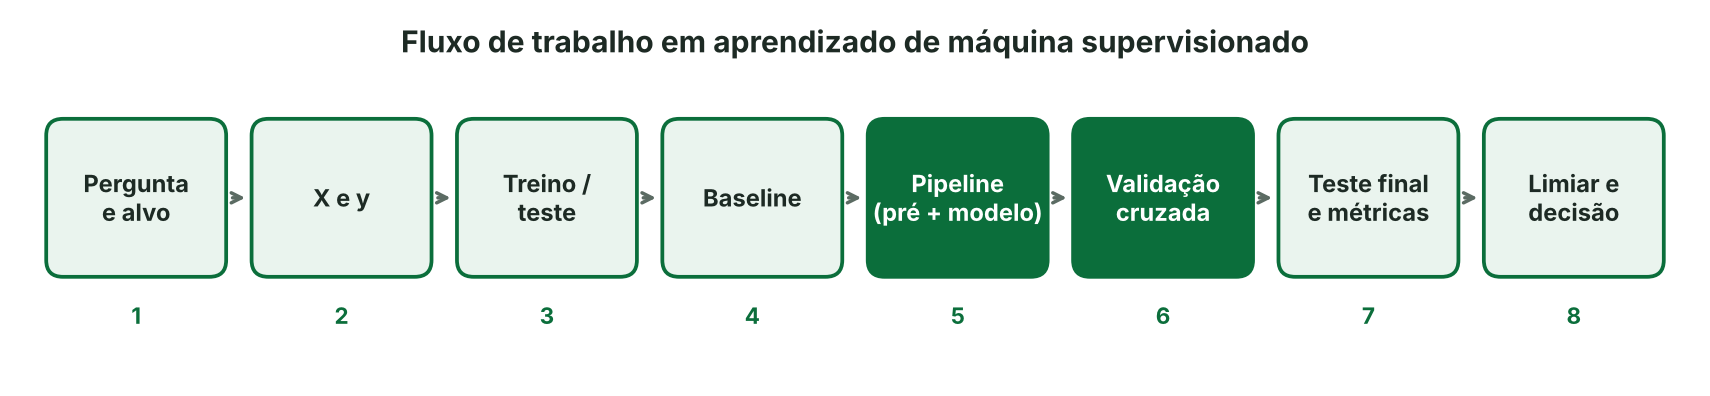

Por que a ordem importa

Cada etapa protege a seguinte: o teste fica guardado, o pré-processamento aprende só no treino e a escolha do modelo é feita na validação cruzada. Assim, o desempenho reportado é o que o modelo terá com dados novos.

4

A API DO SCIKIT-LEARN

### Todo objeto segue o mesmo contrato

Estimador (modelo)

fit(X, y) aprende · predict(X) prevê

predict\_proba(X) dá probabilidades

LogisticRegression, RandomForestClassifier

modelo = LogisticRegression(

    max\_iter=1000)

modelo.fit(X\_treino, y\_treino)

modelo.predict(X\_teste)

modelo.predict\_proba(X\_teste)[:, 1]

modelo.coef\_ # aprendido: termina em \_

Transformador

fit(X) aprende · transform(X) aplica

fit\_transform(X) faz os dois

StandardScaler, OneHotEncoder, SimpleImputer

5

TREINO E TESTE

### Avalie o modelo em dados que ele não viu

X\_treino, X\_teste, y\_treino, y\_teste = train\_test\_split(

    X, y, test\_size=0.25, stratify=y, random\_state=42)

Cuidado: vazamento

O modelo não pode receber informação que não teria no uso real.

• Ajustar padronização ou imputação em TODOS os dados antes de dividir

• Usar uma variável que contém a resposta (ou vem depois dela)

1.125

375

26,9%

usuários no treino

no teste (25%)

cancelaram — igual nos dois (stratify)

6

BASELINE

### O paradoxo da acurácia

73,1%

0

82,7%

acurácia do DummyClassifier: chuta sempre "ficou"

cancelamentos encontrados (recall = 0)

acurácia da regressão logística — e encontra 55 dos 101 que cancelaram

Lição

Com classes desbalanceadas, acurácia alta pode esconder um modelo inútil. Calcule sempre um baseline e escolha a métrica pelo objetivo — aqui, encontrar quem vai cancelar.

7

PRÉ-PROCESSAMENTO + MODELO

### Pipeline: um único estimador

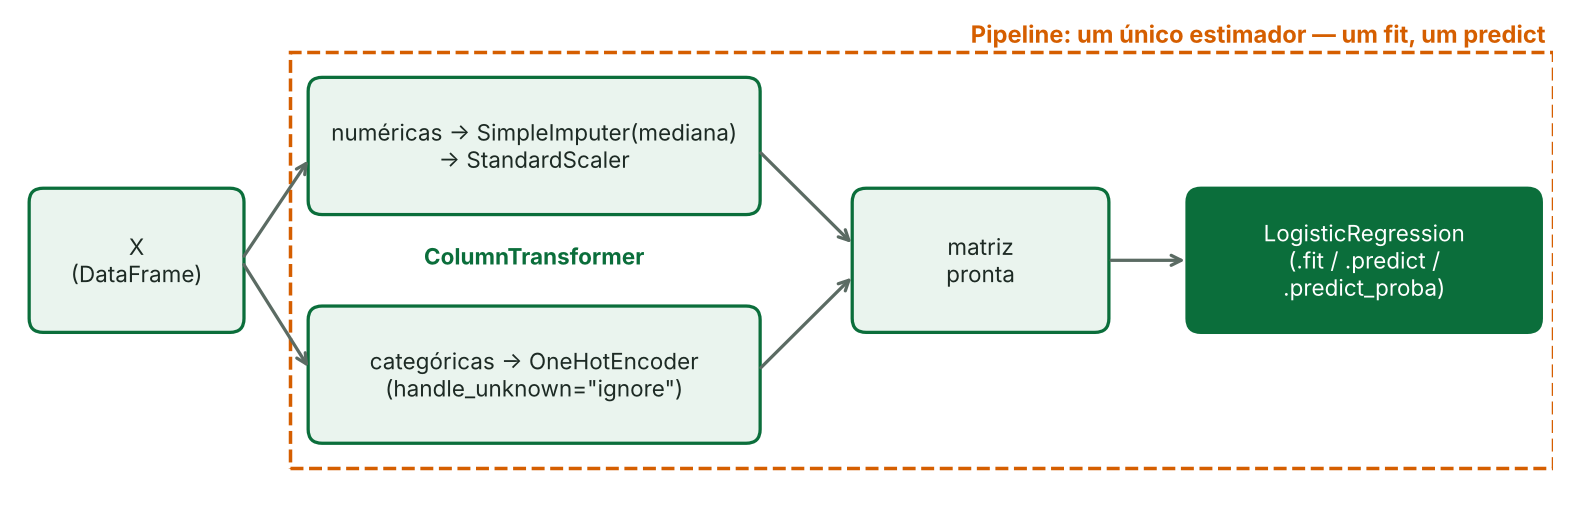

Sem vazamento (inclusive na validação cruzada) · um fit, um predict · trocar o modelo é trocar uma linha

8

O QUE O MODELO APRENDEU

### Quem tem mais risco de cancelar?

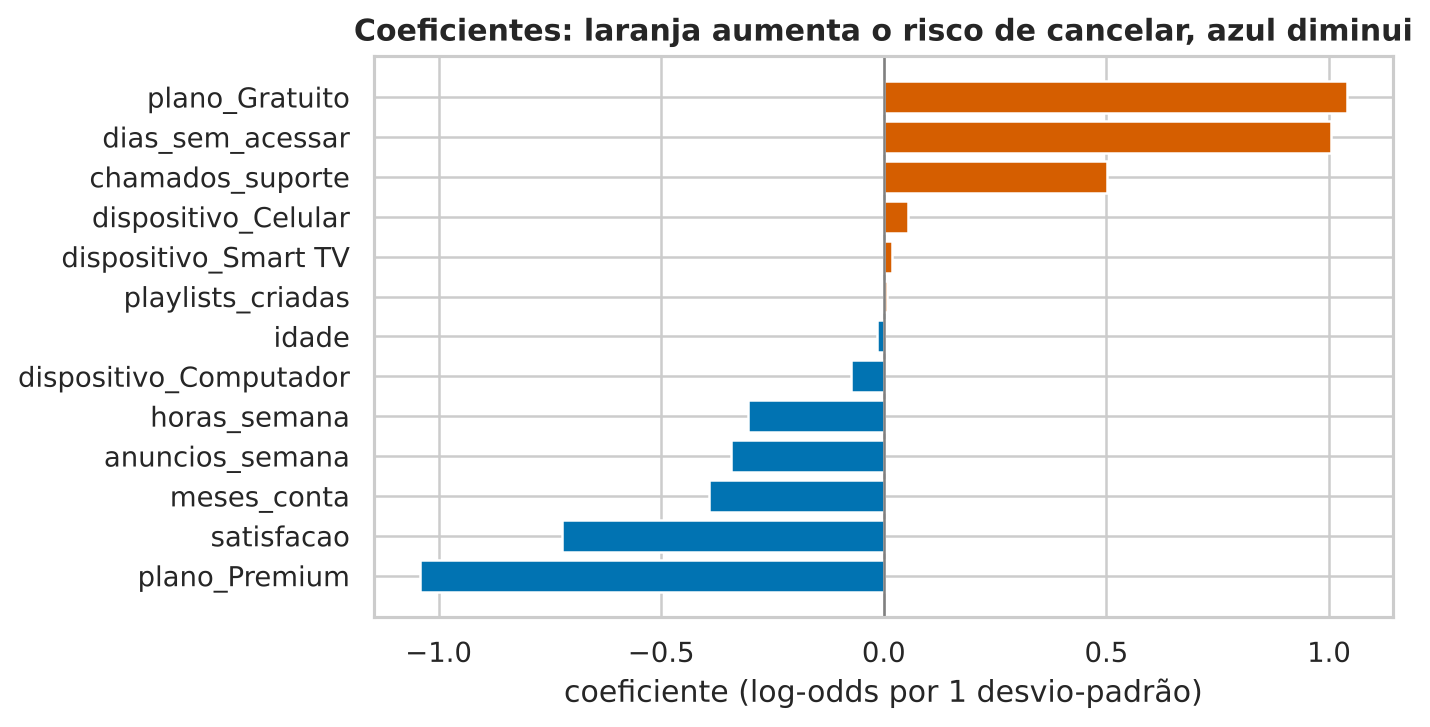

Aumentam o risco

plano gratuito

dias sem acessar

chamados ao suporte

Diminuem o risco

satisfação

meses de conta

plano Premium

Coeficientes de variáveis padronizadas: comparáveis entre si. Associação, não causa.

9

MÉTRICAS DE CLASSIFICAÇÃO

### Tudo começa na matriz de confusão

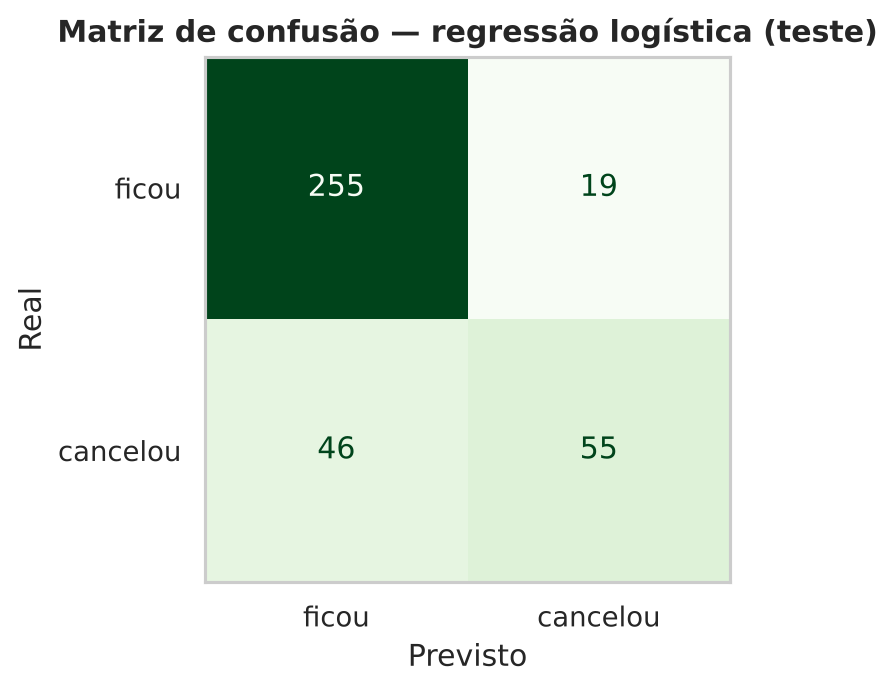

VP = 55

cancelaram e o modelo apontou

FN = 46

cancelaram e o modelo NÃO viu — o erro caro

FP = 19

falso alarme: ficariam, mas foram apontados

VN = 255

ficaram e o modelo acertou

10

PRECISÃO, RECALL E F1

### Cada métrica responde a uma pergunta

| Métrica | Fórmula | Pergunta | Baseline | Logística |
|-----------|----------------------|------------------------------------|------------|-------------|
| Acurácia | (VP + VN) / total | quantos acertos no geral? | 0,731 | 0,827 |
| Precisão | VP / (VP + FP) | dos apontados, quantos cancelaram? | — | 0,743 |
| Recall | VP / (VP + FN) | dos que cancelaram, quantos achei? | 0,000 | 0,545 |
| F1 | 2·P·R / (P + R) | equilíbrio entre precisão e recall | 0,000 | 0,629 |
| ROC-AUC | área sob a curva ROC | o modelo ordena bem o risco? | 0,500 | 0,831 |

Conferindo: precisão = 55 / (55 + 19) = 0,743 · recall = 55 / (55 + 46) = 0,545

11

ROC-AUC E LIMIAR DE DECISÃO

### O limiar é uma decisão de negócio

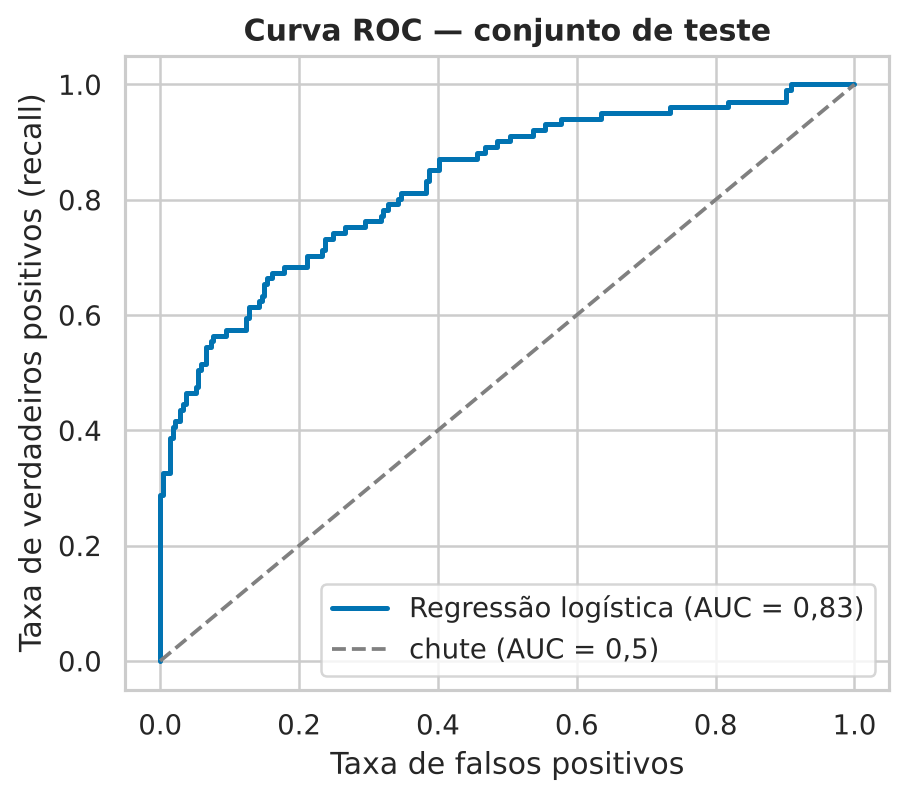

Precisão × recall por limiar



Line chart

| | Precisão | Recall |
|-----|------------|----------|
| 0,2 | 0.46 | 0.802 |
| 0,3 | 0.53 | 0.703 |
| 0,4 | 0.639 | 0.614 |
| 0,5 | 0.743 | 0.545 |
| 0,6 | 0.875 | 0.416 |
| 0,7 | 0.943 | 0.327 |

AUC = 0,83: em 83% dos pares, quem cancelou recebe risco maior. Limiar 0,3 encontra 70% dos cancelamentos (contra 55% em 0,5), com mais falsos alarmes.

12

VALIDAÇÃO CRUZADA

### Comparar modelos sem tocar no teste

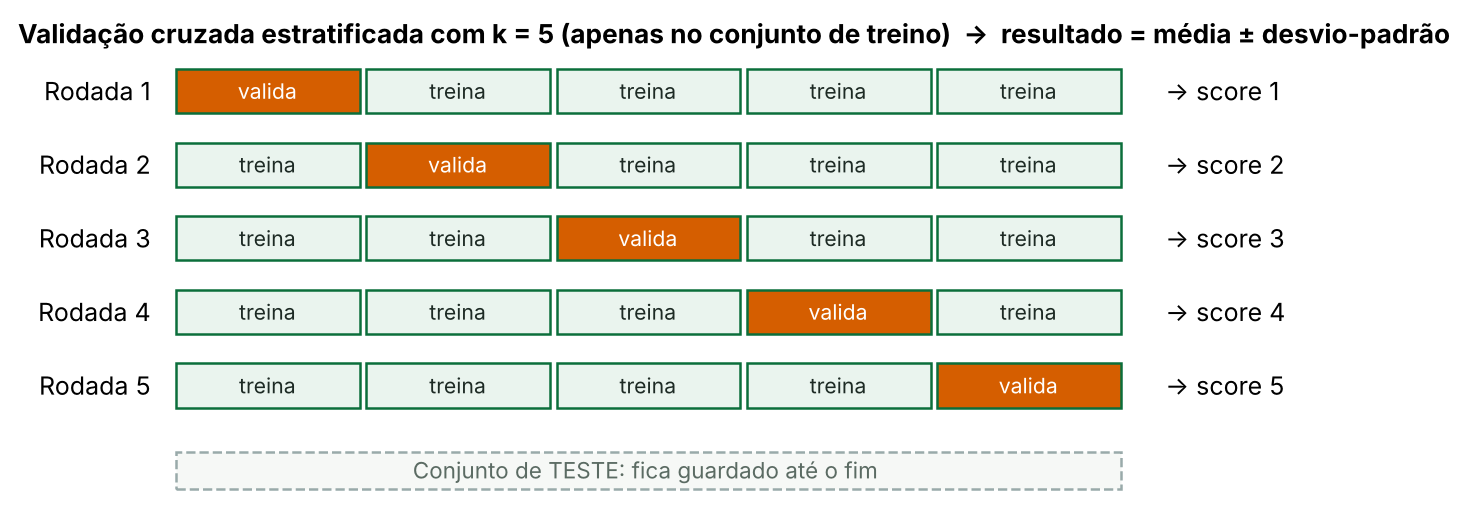

ROC-AUC média (± 0,03 entre folds)



Bar chart

| | ROC-AUC média (5 folds) |
|---------------|---------------------------|
| Baseline | 0.5 |
| Logística | 0.845 |
| Árvore | 0.778 |
| Random forest | 0.838 |

cv = StratifiedKFold(n\_splits=5,

        shuffle=True, random\_state=42)

r = cross\_validate(modelo, X\_treino,

        y\_treino, cv=cv,

        scoring=["accuracy", "f1", "roc\_auc"])

13

MÉTRICAS DE REGRESSÃO

### Prevendo o tempo de entrega da hamburgueria

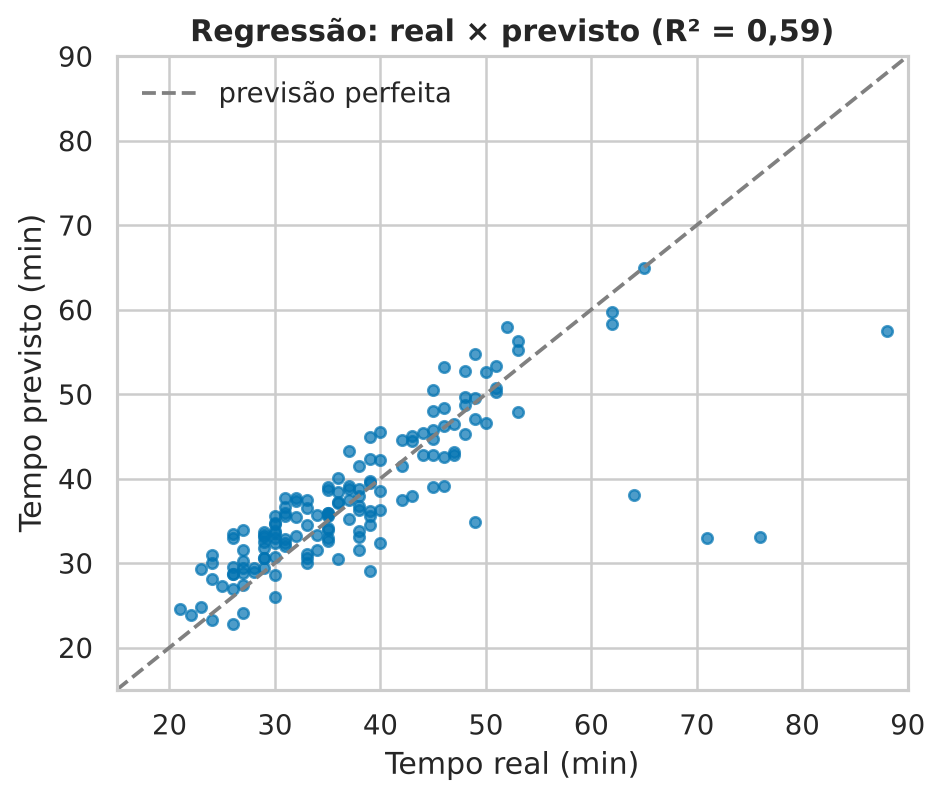

3,9 min

6,8 min

0,59

MAE: erro típico

RMSE (baseline: 10,8 min)

R²

Como ler

MAE: erro médio, na unidade do alvo. RMSE: pune erros grandes — bem acima do MAE indica poucos atrasos enormes. R²: proporção da variação explicada (0 = prever sempre a média).

na validação cruzada:

scoring="neg\_root\_mean\_squared\_error"

14

FECHANDO O RACIOCÍNIO

### Seis erros que o fluxo evita

Avaliar no treino ou reusar o teste para ajustar

Padronizar ou imputar antes de dividir os dados

1

2

Reportar só acurácia em dados desbalanceados

Esquecer stratify=y e random\_state

3

4

Atributo que carrega a resposta (vazamento)

Validação cruzada sem desvio-padrão

5

6

15

DEPOIS DA AULA

### Próximos passos

Trabalho prático (entrega)

Aula14\_Trabalho\_Pratico.ipynb

Classifique os clientes insatisfeitos (nota ≤ 3) da hamburgueria: baseline, pipeline, 2 modelos, validação cruzada e conclusão.

Entregue o .ipynb executado no Moodle.

Formulário avaliativo

10 questões objetivas sobre a aula. Pode consultar o material.

Prazo de ambos

23/11/2026, 23:59

16

AULA 14 — SCIKIT-LEARN: FLUXO DE TRABALHO EM ML

### Dúvidas?

Obrigado pela atenção. Materiais no Moodle: livro, apostila, slides, pacote com notebooks e dados.